# Tutorial 7. A heated building: electric boiler, envelope and weather

![A heated building](../tutorials/images/t07_hero.png)

**Scope:** thermal engineering, building services. **Components:** `ThermalMass`,
`ThermalResistance`, `Convection`, `HeatSource`, `Losses`, `Ambient`, with
`VoltageSource` and `Resistor` for the heater.

## The asset

A small office building heated by a 12 kW electric boiler through a water loop
and radiators. The envelope loses heat through the walls and by ventilation; the
sun and the occupants add some. On a cold day the facilities manager asks:

- **Can the boiler hold 20 °C** at 0 °C outside, and how long does the morning
  warm-up take after a night setback?
- **Where does the heat go?** How is the boiler's power split between the walls
  and the ventilation, and what does the night setback save?

![Thermal network](../tutorials/images/t07_pd.png)

Temperature is the across variable, heat flow the through variable. The heater
is an electrical resistor whose losses, I²R, enter the water as heat through a
`Losses` element; that is how Otwin moves energy from one domain to another when
the physics is one-way.

## Step 1. Build the thermal network

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns

import otwin
from otwin.components.electrical import Ground, Resistor, VoltageSource
from otwin.components.thermal import (
    Ambient,
    Convection,
    HeatSource,
    Losses,
    ThermalMass,
    ThermalResistance,
)

sns.set_theme(style="whitegrid", palette=["#201E1D", "#EC3013", "#4D86A6", "#8A8886"])

P_BOILER, U_MAINS = 12_000.0, 230.0
mains = VoltageSource(None, name="mains")  # V, an input: 230 on, 0 off
element = Resistor(U_MAINS**2 / P_BOILER, name="element")  # ohm: 12 kW at 230 V
gnd = Ground(name="gnd")

water = ThermalMass(
    600.0 * 4186.0, temperature=293.15, name="water"
)  # 600 kg of water in the loop
heater = Losses(element, name="heater")  # the I2R losses, delivered as heat
radiators = Convection(900.0, name="radiators")  # W/K
room = ThermalMass(
    6.0e6, temperature=293.15, name="room"
)  # J/K: air, furniture, inner walls
walls = ThermalResistance(1 / 350.0, name="walls")  # K/W: UA = 350 W/K
ventilation = ThermalResistance(
    1 / 120.0, name="ventilation"
)  # K/W: 0.6 air changes per hour
gains = HeatSource(None, name="gains")  # W, an input: sun and occupants
outdoor = Ambient(273.15, name="outdoor")  # 0 degC

building = gnd >> mains >> element >> gnd
building.connect(water.port, heater.port, radiators.a)
building.connect(radiators.b, room.port, walls.a, ventilation.a, gains.port)
building.connect(walls.b, ventilation.b, outdoor.port)
model = otwin.compile(building)
print(model.summary())
ua_total = 350.0 + 120.0
print(
    f"steady heat need at 20 degC inside, 0 outside: UA dT = {ua_total * 20 / 1e3:.1f} kW of the boiler's {P_BOILER / 1e3:.0f} kW"
)

System: system

Components:
  gnd                          ground [any]
  mains                        voltage_source [electrical]
  element                      resistor [electrical]
  water                        thermal_mass [thermal]
  heater                       losses [thermal]
  radiators                    convection [thermal]
  room                         thermal_mass [thermal]
  walls                        thermal_resistance [thermal]
  ventilation                  thermal_resistance [thermal]
  gains                        heat_source [thermal]
  outdoor                      ambient [thermal]

States:
  water.heat                   stored heat [J]  x0 = 7.36276e+08
  room.heat                    stored heat [J]  x0 = 1.7589e+09

Inputs:
  mains                        voltage [V]
  gains                        heat flow [W]

Constant sources:
  outdoor

Parameters:
  element.resistance           4.40833      ohm
  water.capacity               2.5116e+06   J/K
  radiators.c

Two states: the heat stored in the water and in the room. The heater element is
an electrical resistor; `Losses(element)` takes its I²R and delivers it to the
water. The model is `pseudo-port-hamiltonian`, which is right for a thermal
network: the heat balance is exact, the energy audit is a stability statement.
The steady heat need is below the boiler's rating, so it can hold 20 °C with a
margin to warm up.

## Step 2. Two cold days with a night setback

A thermostat written in Python: the boiler is on when the room is below the set
point, 20 °C from 06:00 to 18:00 and 16 °C at night. Gains are 2 kW in office
hours. The thermostat reads the room state, so the mains voltage is a feedback
input.

In [ ]:
t = np.arange(0, 48 * 3600 + 1, 60.0)
hours = t / 3600
ROOM_INDEX = model.state_names.index("room.heat")


def setpoint(time):
    h = (time / 3600) % 24
    return 293.15 if 6 <= h < 18 else 289.15


def thermostat(time, x):
    room_temperature = x[ROOM_INDEX] / 6.0e6
    return U_MAINS if room_temperature < setpoint(time) else 0.0


def office(time):
    h = (time / 3600) % 24
    return 2000.0 if 8 <= h < 18 else 200.0


run = model.simulate(t=t, inputs={"mains": thermostat, "gains": office})
room_c = run["room.temperature"] - 273.15
water_c = run["water.temperature"] - 273.15
day2 = t >= 24 * 3600
on = run["mains"] > 0
print(
    f"room on day 2: {room_c[day2].min():.1f} to {room_c[day2].max():.1f} degC; water {water_c[day2].min():.0f} to {water_c[day2].max():.0f} degC"
)
warm = t[day2 & (hours % 24 >= 6) & (room_c >= 19.5)]
print(
    f"morning warm-up on day 2: 20 degC reached at {warm[0] / 3600 % 24:.2f} h, {(warm[0] / 3600 % 24 - 6) * 60:.0f} min after the set point changed"
)
print(
    f"boiler duty on day 2: {on[day2].mean():.0%}, energy {np.trapezoid(run['element.power'][day2], t[day2]) / 3.6e6:.0f} kWh"
)
print(
    f"heat through walls {np.trapezoid(run['walls.heat_flow'][day2], t[day2]) / 3.6e6:.0f} kWh, "
    f"ventilation {np.trapezoid(run['ventilation.heat_flow'][day2], t[day2]) / 3.6e6:.0f} kWh, gains {np.trapezoid(run['gains'][day2], t[day2]) / 3.6e6:.0f} kWh"
)

room on day 2: 15.4 to 20.2 degC; water 19 to 32 degC
morning warm-up on day 2: 20 degC reached at 8.55 h, 153 min after the set point changed
boiler duty on day 2: 62%, energy 179 kWh
heat through walls 150 kWh, ventilation 51 kWh, gains 23 kWh


The room holds the day set point and drifts down at night as the setback lets
it. The warm-up time in the morning is set by the room's heat capacity against
the boiler's margin over the losses. The energy accounting closes: boiler energy
plus gains equals the losses through the walls and the ventilation plus the
change in stored heat over the day. Walls take the larger share; that is where
insulation would pay.

## Step 3. Plot the two days

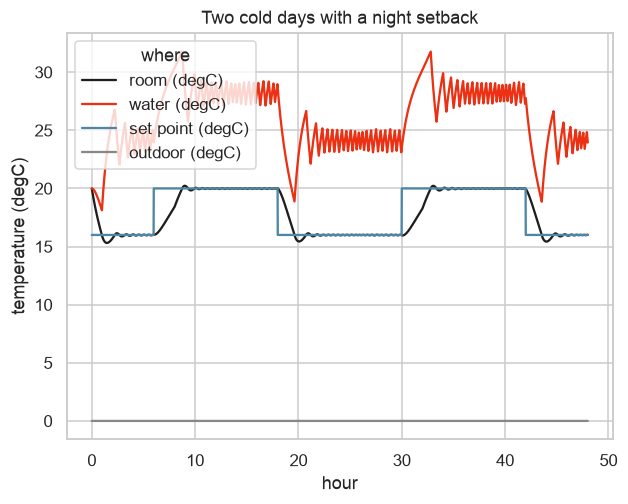

In [ ]:
frame = pd.DataFrame(
    {
        "hour": hours,
        "room (degC)": room_c,
        "water (degC)": water_c,
        "set point (degC)": [setpoint(x) - 273.15 for x in t],
        "outdoor (degC)": 0.0,
    }
)
long = frame.melt("hour", var_name="where", value_name="temperature (degC)")
ax = sns.lineplot(data=long, x="hour", y="temperature (degC)", hue="where")
ax.set_title("Two cold days with a night setback")

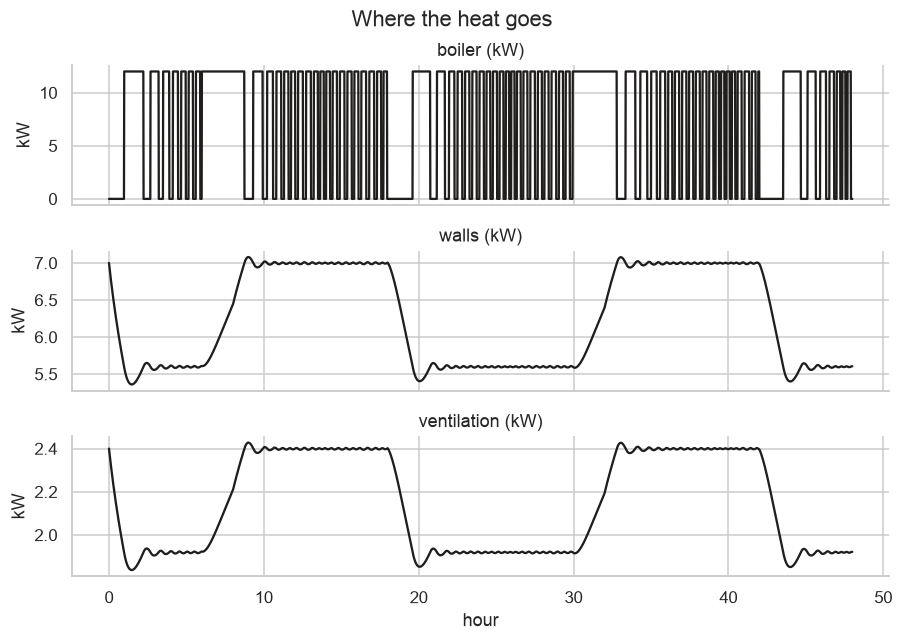

In [ ]:
power = pd.DataFrame(
    {
        "hour": hours,
        "boiler (kW)": run["element.power"] / 1e3,
        "walls (kW)": run["walls.heat_flow"] / 1e3,
        "ventilation (kW)": run["ventilation.heat_flow"] / 1e3,
    }
)
long = power.melt("hour", var_name="flow", value_name="kW")
g = sns.relplot(
    data=long,
    x="hour",
    y="kW",
    row="flow",
    kind="line",
    height=1.9,
    aspect=4.4,
    facet_kws={"sharey": False},
    color="#201E1D",
)
g.set_titles("{row_name}")
g.figure.suptitle("Where the heat goes", y=1.02)

The boiler cycles on and off under the thermostat (the duty printed above is the
fraction of the day it is on). The wall and ventilation losses follow the room
temperature, falling at night.

## Step 4. What the setback saves

Run day 2 again with no setback and compare the boiler energy.

In [ ]:
def thermostat_flat(time, x):
    return U_MAINS if x[ROOM_INDEX] / 6.0e6 < 293.15 else 0.0


flat = model.simulate(t=t, inputs={"mains": thermostat_flat, "gains": office})
e_setback = np.trapezoid(run["element.power"][day2], t[day2]) / 3.6e6
e_flat = np.trapezoid(flat["element.power"][day2], t[day2]) / 3.6e6
print(
    f"boiler energy on day 2: {e_flat:.0f} kWh at a constant 20 degC, {e_setback:.0f} kWh with the night setback "
    f"({(1 - e_setback / e_flat):.0%} saved)"
)

boiler energy on day 2: 202 kWh at a constant 20 degC, 179 kWh with the night setback (12% saved)


The setback saves the fraction printed: the losses are proportional to the
indoor-outdoor difference, so every degree of setback saves in proportion, less
the morning warm-up.

## Step 5. A better envelope

Halve the wall losses (insulation) with `with_parameters` and rerun.

In [ ]:
insulated = model.with_parameters(**{"walls.resistance": 1 / 175.0})
ins = insulated.simulate(t=t, inputs={"mains": thermostat, "gains": office})
print(
    f"insulated: boiler energy {np.trapezoid(ins['element.power'][day2], t[day2]) / 3.6e6:.0f} kWh on day 2 "
    f"(was {e_setback:.0f}), warm-up {((t[day2 & (hours % 24 >= 6) & (ins['room.temperature'] - 273.15 >= 19.5)][0] / 3600) % 24 - 6) * 60:.0f} min"
)

insulated: boiler energy 105 kWh on day 2 (was 179), warm-up 109 min


## What to take from this

- A thermal network is masses joined by resistances and convections; the compiler
  writes the heat balances.
- `Losses` carries the I²R of electrical elements into the thermal domain, one
  way, which is why the model is pseudo-port-Hamiltonian.
- Thermostats and schedules are inputs: functions of time, or of time and state.

Next: [Tutorial 8](08_motor_driven_pump.md) couples three domains in one model.